Iteration:  1 | Best Accuracy: 0.9701
Iteration:  2 | Best Accuracy: 0.9701
Iteration:  3 | Best Accuracy: 0.9701
Iteration:  4 | Best Accuracy: 0.9701
Iteration:  5 | Best Accuracy: 0.9719
Iteration:  6 | Best Accuracy: 0.9719
Iteration:  7 | Best Accuracy: 0.9719
Iteration:  8 | Best Accuracy: 0.9754
Iteration:  9 | Best Accuracy: 0.9754
Iteration: 10 | Best Accuracy: 0.9754

CUCKOO SEARCH OPTIMIZATION RESULTS
Best C: 93.56206
Best Gamma: 0.0007079
Best Accuracy: 0.9754

Final SVM Model Trained Successfully!


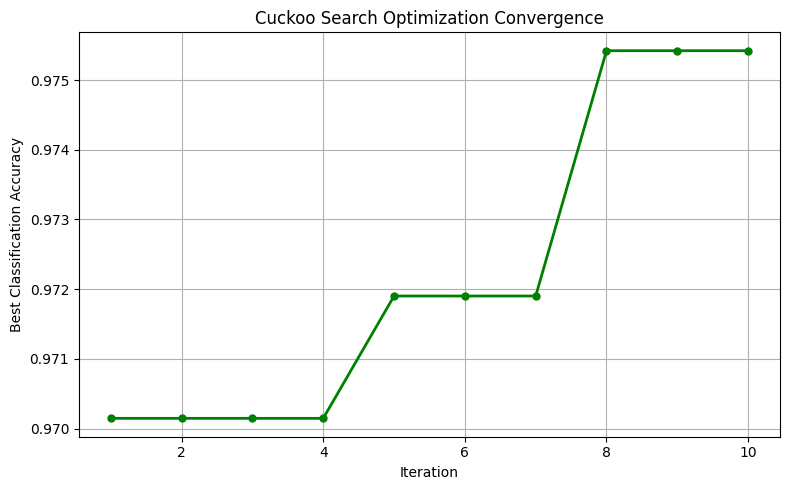

In [1]:

import math
import numpy as np
import random
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    cross_val_score,
    StratifiedKFold
)

# ============================================================
# CUCKOO SEARCH OPTIMIZATION (CSO)
# SVM HYPERPARAMETER OPTIMIZATION
# ============================================================

# 1. Set Random Seeds
random.seed(42)
np.random.seed(42)

# 2. Load Breast Cancer Dataset
data = load_breast_cancer()

X = data.data
y = data.target

# 3. Initialize Parameters
N = 8
ITERATIONS = 10
PA = 0.25
DIM = 2

lower_bounds = np.array([-3, -4])
upper_bounds = np.array([3, 1])

# 4. Levy Flight Function
def levy_flight():

    beta = 1.5

    sigma = (
        math.gamma(1 + beta) * math.sin(math.pi * beta / 2) /
        (
            math.gamma((1 + beta) / 2) *
            beta *
            2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, DIM)
    v = np.random.normal(0, 1, DIM)

    step = u / (np.abs(v) ** (1 / beta))

    return step


# 5. Fitness Function
def fitness(nest):

    # Convert search variables into SVM parameters
    C = 10 ** nest[0]
    gamma = 10 ** nest[1]

    # Create SVM model with feature scaling
    model = make_pipeline(
        StandardScaler(),
        SVC(C=C, gamma=gamma, kernel='rbf')
    )

    # Stratified 3-fold cross-validation
    cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring='accuracy'
    )

    # Return mean accuracy
    return scores.mean()


# 6. Initialize Random Nests
nests = np.random.uniform(
    lower_bounds,
    upper_bounds,
    (N, DIM)
)

scores = np.array([
    fitness(nest) for nest in nests
])

# Store best accuracy history
history = []

# Initialize global best
best_index = np.argmax(scores)

best_nest = nests[best_index].copy()
best_score = scores[best_index]


# ============================================================
# 7. CUCKOO SEARCH MAIN LOOP
# ============================================================

for iteration in range(ITERATIONS):

    # Generate a new cuckoo using Levy flight
    k = random.randrange(N)

    new_nest = (
        nests[k] + 0.1 * levy_flight()
    )

    # Apply boundary constraints
    new_nest = np.clip(
        new_nest,
        lower_bounds,
        upper_bounds
    )

    # Evaluate new nest
    new_score = fitness(new_nest)

    # Select a random nest
    j = random.randrange(N)

    # Replace nest if new solution is better
    if new_score > scores[j]:

        nests[j] = new_nest.copy()
        scores[j] = new_score

    # Abandon a fraction of poor nests
    count = max(1, int(PA * N))

    worst_indices = np.argsort(scores)[:count]

    for i in worst_indices:

        nests[i] = np.random.uniform(
            lower_bounds,
            upper_bounds
        )

        scores[i] = fitness(nests[i])

    # Update global best
    current_best = np.argmax(scores)

    if scores[current_best] > best_score:

        best_score = scores[current_best]
        best_nest = nests[current_best].copy()

    # Store best accuracy
    history.append(best_score)

    # Display iteration results
    print(
        f"Iteration: {iteration + 1:2d} | "
        f"Best Accuracy: {best_score:.4f}"
    )


# ============================================================
# 8. FINAL BEST SOLUTION
# ============================================================

best_C = 10 ** best_nest[0]
best_gamma = 10 ** best_nest[1]

print("\n====================================")
print("CUCKOO SEARCH OPTIMIZATION RESULTS")
print("====================================")

print("Best C:", round(best_C, 5))
print("Best Gamma:", round(best_gamma, 7))
print("Best Accuracy:", round(best_score, 4))


# ============================================================
# 9. TRAIN FINAL SVM MODEL
# ============================================================

final_model = make_pipeline(
    StandardScaler(),
    SVC(
        C=best_C,
        gamma=best_gamma,
        kernel='rbf'
    )
)

final_model.fit(X, y)

print("\nFinal SVM Model Trained Successfully!")


# ============================================================
# 10. PLOT CONVERGENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, ITERATIONS + 1),
    history,
    color='green',
    linewidth=2,
    marker='o',
    markersize=5
)

plt.title("Cuckoo Search Optimization Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Classification Accuracy")

plt.grid(True)
plt.tight_layout()
plt.show()
